# MODEL BUILDING - ChurnShield AI — Explainable Customer Retention & Revenue Intelligence Platform

## IMPORT 

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings

from pathlib import Path
# Import Model Evaluation Metrics

from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,confusion_matrix,classification_report)

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

## Load datasets

In [3]:
X_train = pd.read_csv("X_train.csv")
X_test = pd.read_csv("X_test.csv")
y_train = pd.read_csv("y_train.csv").squeeze()
y_test = pd.read_csv("y_test.csv").squeeze()


In [4]:
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)
print("Target Distribution:")
print(y_train.value_counts())

Training Data: (5634, 29)
Testing Data: (1409, 29)
Target Distribution:
ChurnFlag
0    4139
1    1495
Name: count, dtype: int64


## DATA VALIDATION

In [5]:
print("Missing Values in X_train:",X_train.isnull().sum().sum())

print("Missing Values in X_test:",X_test.isnull().sum().sum())

Missing Values in X_train: 0
Missing Values in X_test: 0


In [40]:
print("\nDuplicate Rows in X_train:",X_train.duplicated().sum())

print("Duplicate Rows in X_test:",X_test.duplicated().sum())


Duplicate Rows in X_train: 26
Duplicate Rows in X_test: 2


In [41]:
print("\nTraining and Testing Columns Match:",list(X_train.columns) == list(X_test.columns))



Training and Testing Columns Match: True


In [42]:
print("\nUnique Classes in y_train:",sorted(y_train.unique()))

print("Unique Classes in y_test:",sorted(y_test.unique()))


Unique Classes in y_train: [np.int64(0), np.int64(1)]
Unique Classes in y_test: [np.int64(0), np.int64(1)]


## IMPORT MACHINE LEARNING MODELS

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier,GradientBoostingClassifier)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from xgboost import XGBClassifier

##  DEFINE MACHINE LEARNING MODELS

In [44]:

models = {

    "Logistic Regression": LogisticRegression(class_weight="balanced",max_iter=1000,random_state=42),

    "Decision Tree": DecisionTreeClassifier(class_weight="balanced",random_state=42),

    "Random Forest": RandomForestClassifier(n_estimators=200,class_weight="balanced",random_state=42,n_jobs=-1),

    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100,learning_rate=0.1,random_state=42),

    "XGBoost": XGBClassifier(n_estimators=200,learning_rate=0.05,max_depth=4,subsample=0.8,colsample_bytree=0.8,eval_metric="logloss",random_state=42),

    "Support Vector Machine": SVC(class_weight="balanced",probability=True,random_state=42),

    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5,n_jobs=-1)
}

print("Total Models:", len(models))

for name in models:
    print("-", name)

Total Models: 7
- Logistic Regression
- Decision Tree
- Random Forest
- Gradient Boosting
- XGBoost
- Support Vector Machine
- K-Nearest Neighbors


## TRAIN MACHINE LEARNING MODELS

In [45]:
trained_models = {}

for name, model in models.items():

    print(f"Training {name}...")

    model.fit(X_train, y_train)

    trained_models[name] = model

    print(f"{name} training completed!\n")

Training Logistic Regression...
Logistic Regression training completed!

Training Decision Tree...
Decision Tree training completed!

Training Random Forest...
Random Forest training completed!

Training Gradient Boosting...
Gradient Boosting training completed!

Training XGBoost...
XGBoost training completed!

Training Support Vector Machine...
Support Vector Machine training completed!

Training K-Nearest Neighbors...
K-Nearest Neighbors training completed!



##  EVALUATE ALL INITIAL MODELS

In [49]:
initial_results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    y_prob = model.predict_proba(X_test)[:, 1]

    initial_results.append({

        "Model": name,

        "Accuracy": accuracy_score(y_test, y_pred),

        "Precision": precision_score(y_test, y_pred, zero_division=0),

        "Recall": recall_score(y_test, y_pred, zero_division=0),

        "F1-Score": f1_score(y_test, y_pred, zero_division=0),

        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })


initial_results_df = pd.DataFrame(initial_results)

initial_results_df = initial_results_df.sort_values(by="F1-Score",ascending=False).reset_index(drop=True)

display(initial_results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Support Vector Machine,0.7523,0.5221,0.7888,0.6283,0.8246
1,Logistic Regression,0.7353,0.5008,0.7941,0.6143,0.8415
2,XGBoost,0.8013,0.6546,0.5321,0.5870,0.8451
3,Gradient Boosting,0.8041,0.6750,0.5053,0.5780,0.8438
4,K-Nearest Neighbors,0.7679,0.5677,0.5267,0.5465,0.7850
5,Random Forest,0.7800,0.6096,0.4759,0.5345,0.8240
6,Decision Tree,0.7395,0.5093,0.5107,0.5100,0.6670


##  MODEL PERFORMANCE COMPARISON

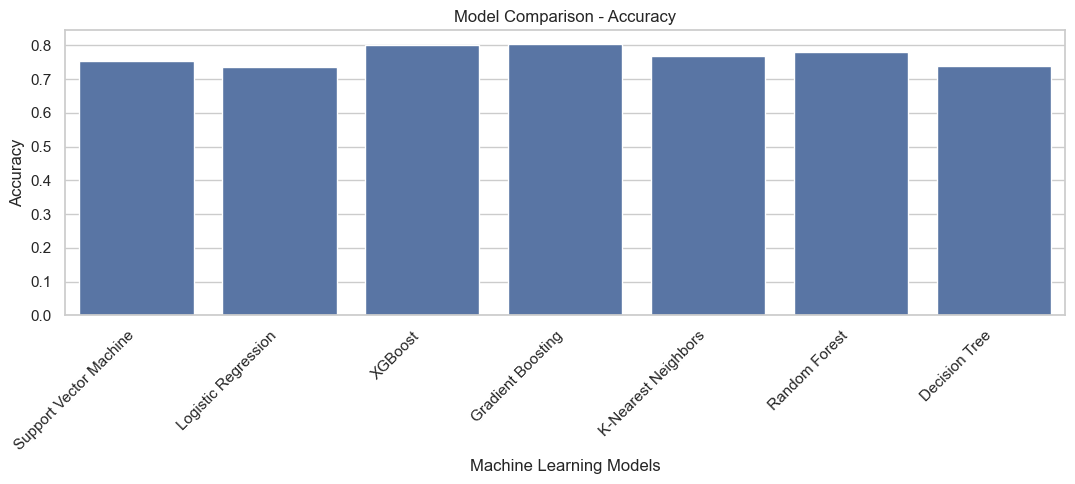

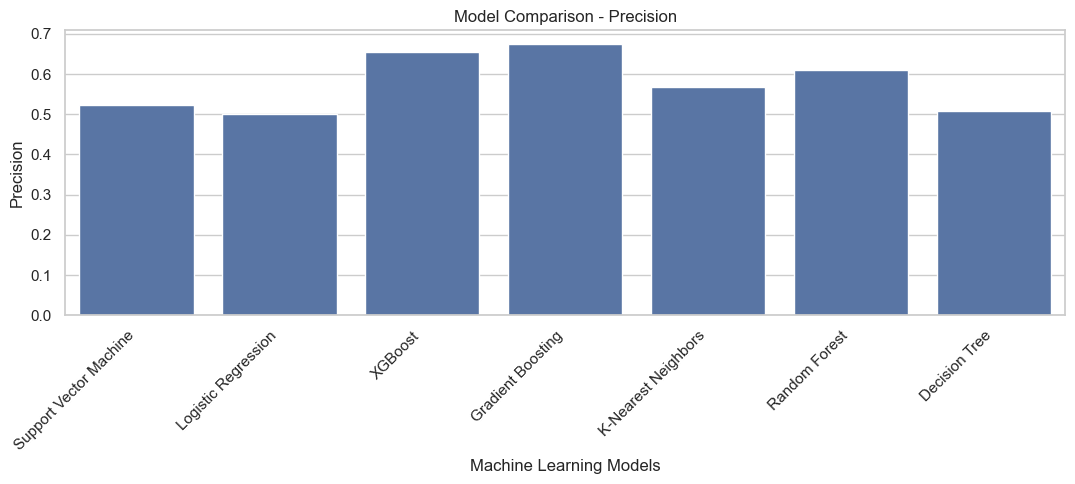

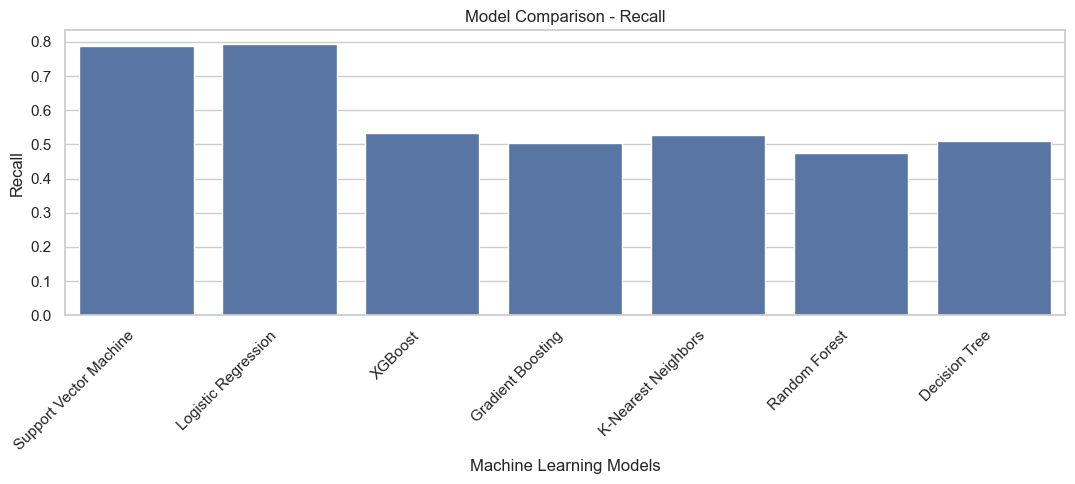

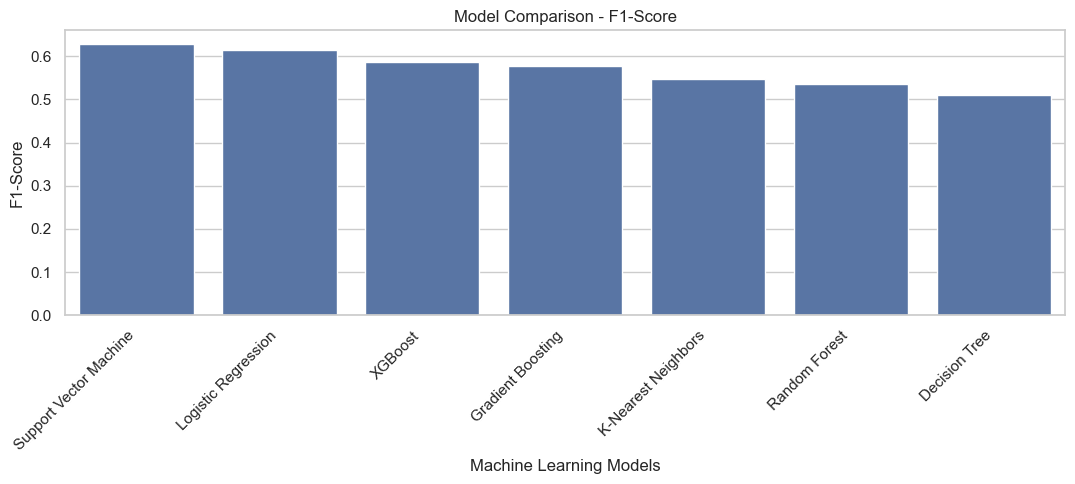

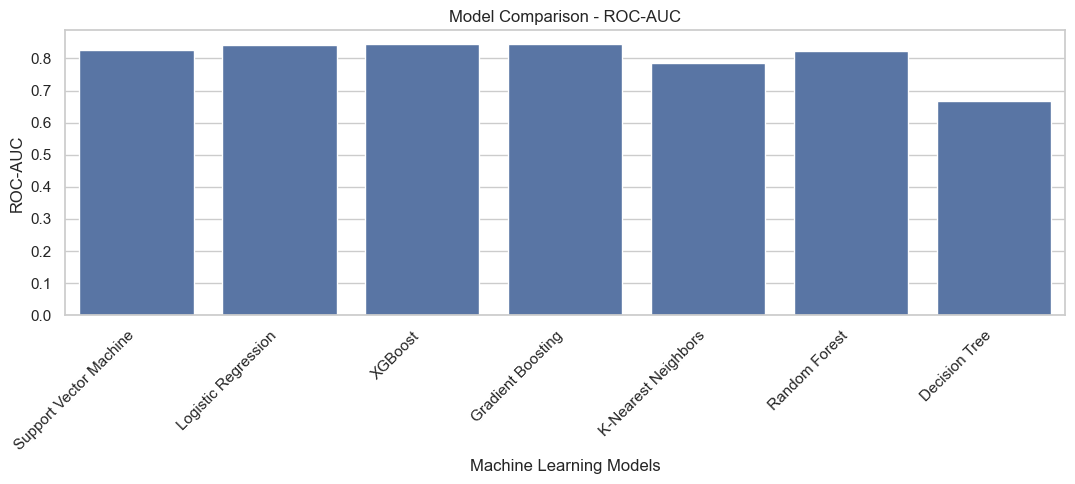

In [50]:
metrics = ["Accuracy","Precision","Recall","F1-Score","ROC-AUC"]

for metric in metrics:

    plt.figure(figsize=(11, 5))

    sns.barplot(data=initial_results_df,x="Model",y=metric)

    plt.title(f"Model Comparison - {metric}")
    plt.xlabel("Machine Learning Models")
    plt.ylabel(metric)

    plt.xticks(rotation=45, ha="right")

    plt.tight_layout()
    plt.show()

## CONFUSION MATRIX COMPARISON

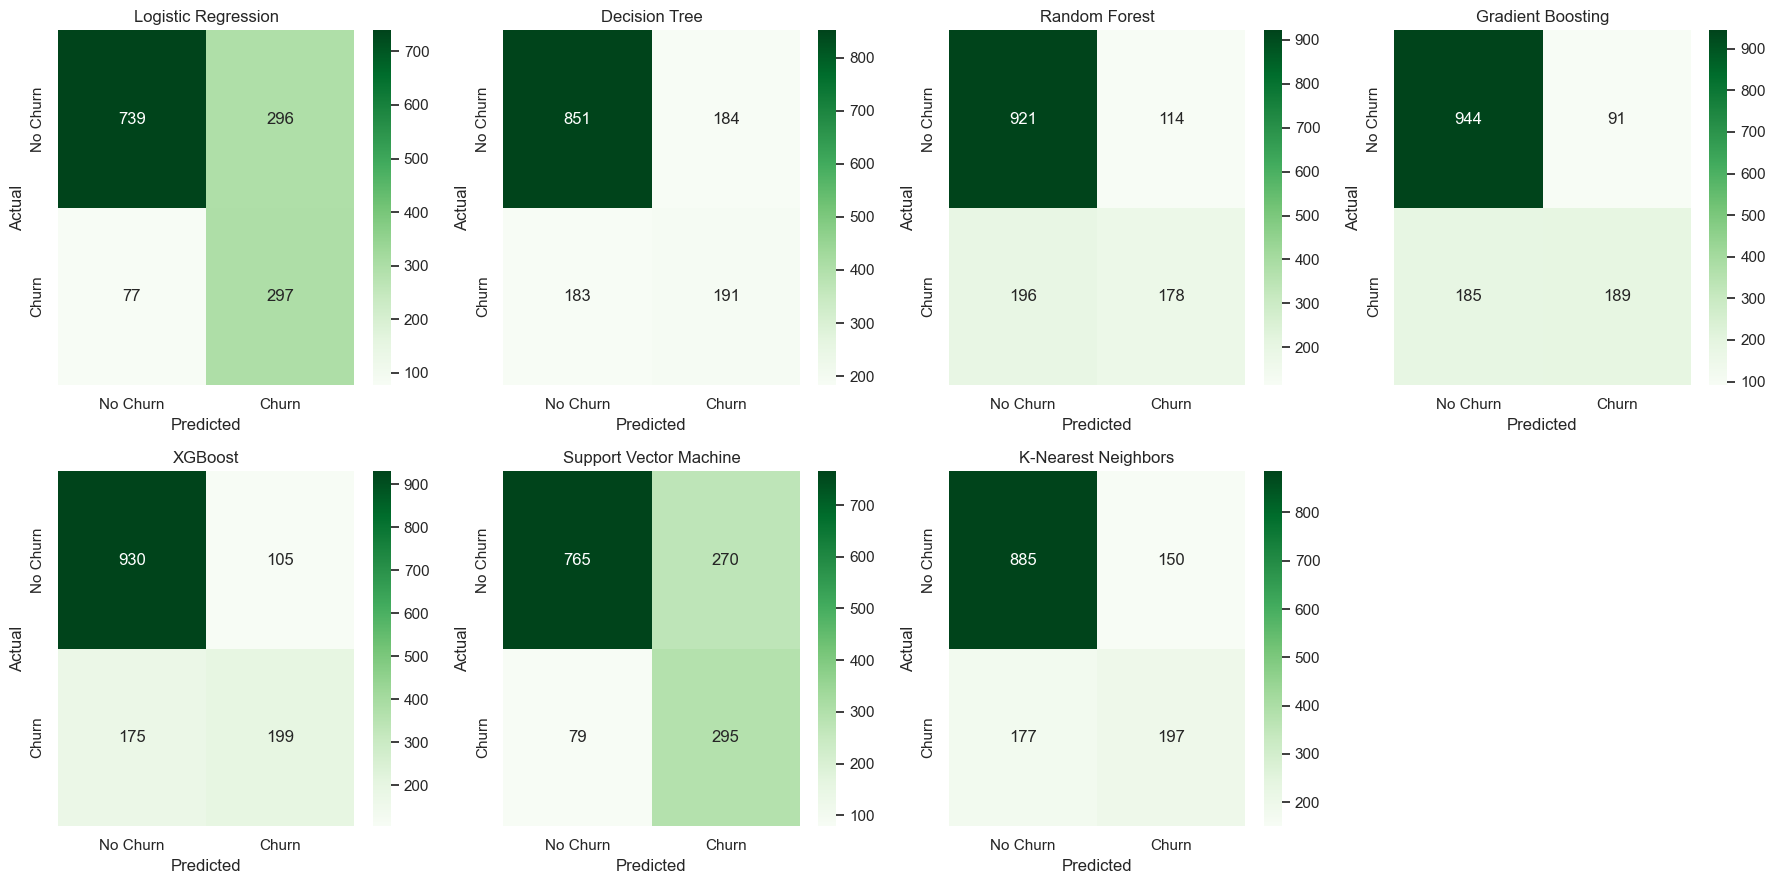

In [53]:
fig, axes = plt.subplots(2, 4,figsize=(18, 9))

axes = axes.flatten()

for index, (name, model) in enumerate(trained_models.items()):

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(cm,annot=True,fmt="d",cmap="Greens",xticklabels=["No Churn", "Churn"],yticklabels=["No Churn", "Churn"],ax=axes[index])

    axes[index].set_title(name)
    axes[index].set_xlabel("Predicted")
    axes[index].set_ylabel("Actual")


# Hide unused subplot
for index in range(len(trained_models), len(axes)):
    axes[index].axis("off")

plt.tight_layout()
plt.show()

## ROC CURVE COMPARISON

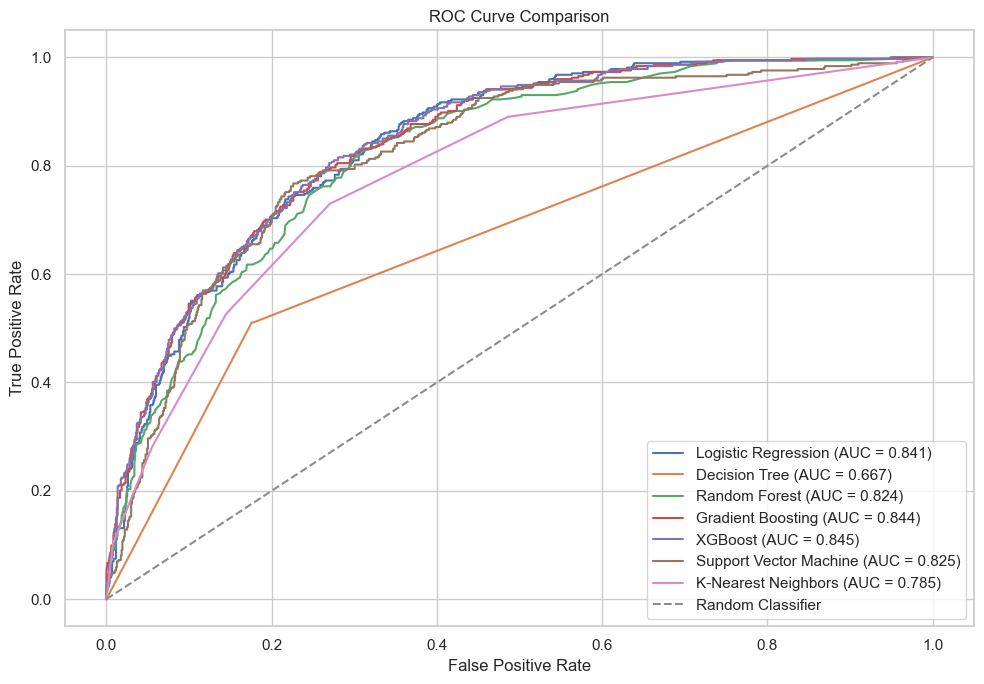

In [54]:
plt.figure(figsize=(10, 7))

for name, model in trained_models.items():

    y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test,y_prob)

    roc_auc = auc(fpr, tpr)

    plt.plot(fpr,tpr,label=f"{name} (AUC = {roc_auc:.3f})")


plt.plot([0, 1],[0, 1],linestyle="--",label="Random Classifier")

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## PRECISION-RECALL CURVE COMPARISON

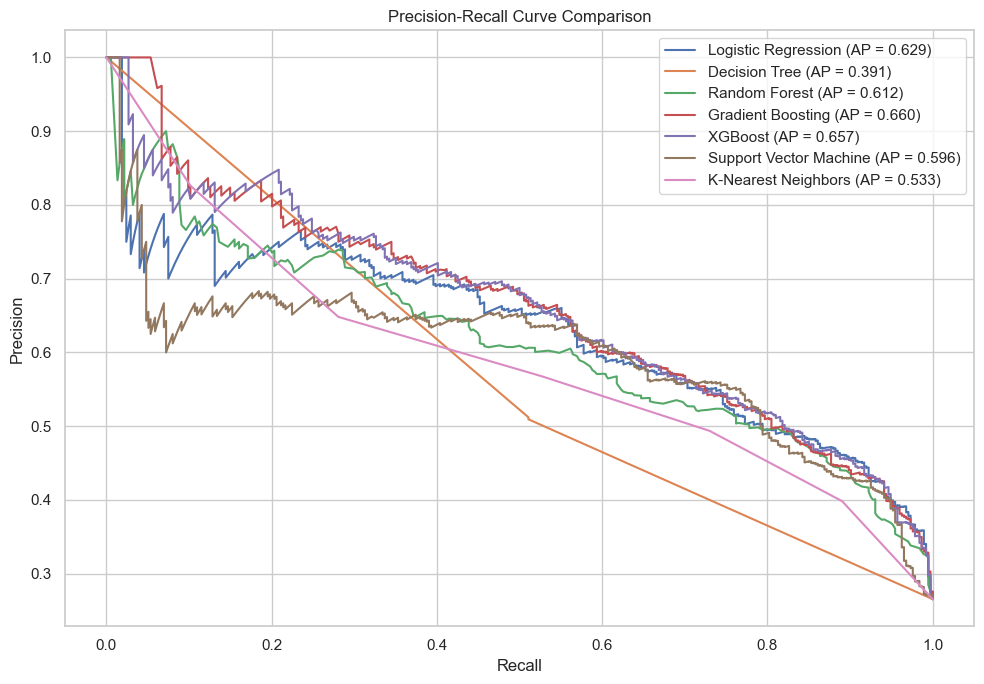

In [56]:
plt.figure(figsize=(10, 7))

for name, model in trained_models.items():

    y_prob = model.predict_proba(X_test)[:, 1]

    precision, recall, thresholds = precision_recall_curve(y_test,y_prob)

    ap_score = average_precision_score(y_test,y_prob)

    plt.plot(recall,precision,label=f"{name} (AP = {ap_score:.3f})")


plt.title("Precision-Recall Curve Comparison")
plt.xlabel("Recall")
plt.ylabel("Precision")

plt.legend(loc="best")
plt.tight_layout()
plt.show()

## IMPORT HYPERPARAMETER TUNING LIBRARIES

In [57]:
from sklearn.model_selection import (RandomizedSearchCV,StratifiedKFold)

##  DEFINE HYPERPARAMETER SEARCH

In [58]:
scale_pos_weight = (
    (y_train == 0).sum() / (y_train == 1).sum())

param_grids = {

    "Logistic Regression": {
        "C": [0.01, 0.1, 1, 10, 100]
    },

    "SVM": {
        "C": [0.1, 1, 10, 100],
        "gamma": ["scale", "auto"],
        "kernel": ["rbf"]
    },

    "XGBoost": {
        "n_estimators": [100, 200, 300],
        "max_depth": [3, 4, 5, 6],
        "learning_rate": [0.01, 0.05, 0.1],
        "subsample": [0.8, 1.0],
        "colsample_bytree": [0.8, 1.0],
        "scale_pos_weight": [1, scale_pos_weight]
    }
}

print("XGBoost scale_pos_weight:", round(scale_pos_weight, 2))

XGBoost scale_pos_weight: 2.77


## HYPERPARAMETER TUNING

In [59]:
tuning_models = {
    "Logistic Regression": trained_models["Logistic Regression"],
    "SVM": trained_models["Support Vector Machine"],
    "XGBoost": trained_models["XGBoost"]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

best_models = {}
tuning_results = []

for name, model in tuning_models.items():

    print(f"\nTuning {name}...")

    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=param_grids[name],
        n_iter=10,
        scoring="f1",
        cv=cv,
        random_state=42,
        n_jobs=-1,
        verbose=1
    )

    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best CV F1-Score": search.best_score_,
        "Best Parameters": search.best_params_
    })

    print(f"{name} tuning completed!")
    print("Best CV F1-Score:", round(search.best_score_, 4))
    print("Best Parameters:", search.best_params_)



Tuning Logistic Regression...
Fitting 3 folds for each of 5 candidates, totalling 15 fits
Logistic Regression tuning completed!
Best CV F1-Score: 0.6319
Best Parameters: {'C': 0.01}

Tuning SVM...
Fitting 3 folds for each of 8 candidates, totalling 24 fits
SVM tuning completed!
Best CV F1-Score: 0.6263
Best Parameters: {'kernel': 'rbf', 'gamma': 'scale', 'C': 0.1}

Tuning XGBoost...
Fitting 3 folds for each of 10 candidates, totalling 30 fits
XGBoost tuning completed!
Best CV F1-Score: 0.6354
Best Parameters: {'subsample': 0.8, 'scale_pos_weight': np.float64(2.768561872909699), 'n_estimators': 300, 'max_depth': 6, 'learning_rate': 0.01, 'colsample_bytree': 0.8}


## HYPERPARAMETER TUNING

In [61]:
tuned_results = []

for name, model in best_models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    tuned_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

tuned_results_df = pd.DataFrame(tuned_results)

tuned_results_df = tuned_results_df.sort_values(by="F1-Score",ascending=False).reset_index(drop=True)

tuned_results_df.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,XGBoost,0.7580,0.5296,0.7888,0.6337,0.8460
1,Logistic Regression,0.7495,0.5184,0.7914,0.6265,0.8390
2,SVM,0.7452,0.5129,0.7995,0.6249,0.8325


## BEFORE AND AFTER TUNING COMPARISON

In [62]:
before_after_results = []

model_mapping = {
    "Logistic Regression": "Logistic Regression",
    "SVM": "Support Vector Machine",
    "XGBoost": "XGBoost"
}

for tuned_name, original_name in model_mapping.items():

    before = initial_results_df[initial_results_df["Model"] == original_name].iloc[0]

    after = tuned_results_df[tuned_results_df["Model"] == tuned_name].iloc[0]

    for stage, result in [("Before Tuning", before),("After Tuning", after)]:

        before_after_results.append({

            "Model": tuned_name,
            "Stage": stage,
            "Accuracy": result["Accuracy"],
            "Precision": result["Precision"],
            "Recall": result["Recall"],
            "F1-Score": result["F1-Score"],
            "ROC-AUC": result["ROC-AUC"]
        })


before_after_df = pd.DataFrame(before_after_results)

display(before_after_df.round(4))

,Model,Stage,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,Before Tuning,0.7353,0.5008,0.7941,0.6143,0.8415
1,Logistic Regression,After Tuning,0.7495,0.5184,0.7914,0.6265,0.8390
2,SVM,Before Tuning,0.7523,0.5221,0.7888,0.6283,0.8246
3,SVM,After Tuning,0.7452,0.5129,0.7995,0.6249,0.8325
4,XGBoost,Before Tuning,0.8013,0.6546,0.5321,0.5870,0.8451
5,XGBoost,After Tuning,0.7580,0.5296,0.7888,0.6337,0.8460


## CLASSIFICATION REPORTS FOR TUNED MODELS

In [63]:
for name, model in best_models.items():

    print("\n" + "=" * 60)
    print(f"TUNED MODEL: {name}")
    print("=" * 60)

    y_pred = model.predict(X_test)

    print(classification_report(y_test,y_pred,target_names=["No Churn", "Churn"],zero_division=0))


TUNED MODEL: Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.91      0.73      0.81      1035
       Churn       0.52      0.79      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409


TUNED MODEL: SVM
              precision    recall  f1-score   support

    No Churn       0.91      0.73      0.81      1035
       Churn       0.51      0.80      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409


TUNED MODEL: XGBoost
              precision    recall  f1-score   support

    No Churn       0.91      0.75      0.82      1035
       Churn       0.53      0.79      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409


## SELECT FINAL MODEL

In [65]:
final_model = best_models["XGBoost"]

print("Selected Final Model: XGBoost")

# Generate final predictions

y_final_pred = final_model.predict(X_test)

y_final_prob = final_model.predict_proba(X_test)[:, 1]

print("\nFinal Model Performance:")

print("Accuracy:",round(accuracy_score(y_test, y_final_pred), 4))

print("Precision:",round(precision_score(y_test, y_final_pred), 4))

print("Recall:",round(recall_score(y_test, y_final_pred), 4))

print("F1-Score:",round(f1_score(y_test, y_final_pred), 4))

print("ROC-AUC:",round(roc_auc_score(y_test, y_final_prob), 4))

Selected Final Model: XGBoost

Final Model Performance:
Accuracy: 0.758
Precision: 0.5296
Recall: 0.7888
F1-Score: 0.6337
ROC-AUC: 0.846


## FINAL MODEL CONFUSION MATRIX

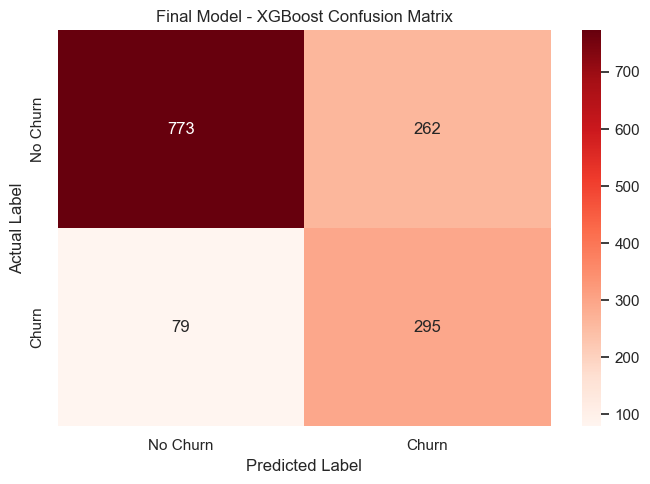

In [70]:
cm = confusion_matrix(y_test, y_final_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(cm,annot=True,fmt="d",cmap="Reds",xticklabels=["No Churn", "Churn"],yticklabels=["No Churn", "Churn"])

plt.title("Final Model - XGBoost Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

## CONFUSION MATRIX - PERFORMANCE BREAKDOWN

In [71]:
tn, fp, fn, tp = cm.ravel()

print("True Negative (TN):", tn)
print("False Positive (FP):", fp)
print("False Negative (FN):", fn)
print("True Positive (TP):", tp)

print("\nBusiness Interpretation:")
print("Correctly identified No Churn:", tn)
print("Incorrectly predicted Churn:", fp)
print("Missed Churn Customers:", fn)
print("Correctly identified Churn:", tp)

True Negative (TN): 773
False Positive (FP): 262
False Negative (FN): 79
True Positive (TP): 295

Business Interpretation:
Correctly identified No Churn: 773
Incorrectly predicted Churn: 262
Missed Churn Customers: 79
Correctly identified Churn: 295


## THRESHOLD OPTIMIZATION

In [73]:
from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.metrics import precision_score, recall_score, f1_score

In [74]:
# 1. Split training data into training and validation sets

X_subtrain, X_val, y_subtrain, y_val = train_test_split(X_train,y_train,test_size=0.20,random_state=42,stratify=y_train)

print("Sub-training data:", X_subtrain.shape)
print("Validation data:", X_val.shape)

# 2. Create a fresh copy of the tuned XGBoost model

validation_model = clone(best_models["XGBoost"])

# 3. Train the model using sub-training data

validation_model.fit(X_subtrain, y_subtrain)

# 4. Get churn probabilities for validation data

y_val_prob = validation_model.predict_proba(X_val)[:, 1]

# 5. Test different probability thresholds

threshold_results = []

for threshold in np.arange(0.20, 0.81, 0.01):

    y_val_pred = (y_val_prob >= threshold).astype(int)

    precision = precision_score(y_val, y_val_pred, zero_division=0)

    recall = recall_score(y_val, y_val_pred, zero_division=0)

    f1 = f1_score(y_val, y_val_pred, zero_division=0)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

# 6. Create threshold comparison table

threshold_df = pd.DataFrame(threshold_results)

# 7. Select threshold with highest validation F1-score

best_threshold_row = threshold_df.loc[threshold_df["F1-Score"].idxmax()]

best_threshold = best_threshold_row["Threshold"]

print("\nBest Threshold:", best_threshold)

print("\nBest Validation Performance:")

print(best_threshold_row)

Sub-training data: (4507, 29)
Validation data: (1127, 29)

Best Threshold: 0.61

Best Validation Performance:
Threshold    0.610000
Precision    0.633028
Recall       0.692308
F1-Score     0.661342
Name: 41, dtype: float64


In [75]:
from sklearn.base import clone

In [76]:
# 1. Create a fresh XGBoost model with tuned parameters

final_model = clone(best_models["XGBoost"])

# 2. Train using the complete training dataset

final_model.fit(X_train, y_train)

# 3. Predict churn probabilities on test data

y_final_prob = final_model.predict_proba(X_test)[:, 1]

# 4. Apply optimized threshold

y_final_pred = (y_final_prob >= best_threshold).astype(int)


In [77]:
# 5. Evaluate final model

print("FINAL XGBOOST MODEL PERFORMANCE")
print("=" * 45)

print("Selected Threshold:", best_threshold)

print("Accuracy:",
      round(accuracy_score(y_test, y_final_pred), 4))

print("Precision:",
      round(precision_score(y_test, y_final_pred), 4))

print("Recall:",
      round(recall_score(y_test, y_final_pred), 4))

print("F1-Score:",
      round(f1_score(y_test, y_final_pred), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, y_final_prob), 4))

FINAL XGBOOST MODEL PERFORMANCE
Selected Threshold: 0.61
Accuracy: 0.7793
Precision: 0.5731
Recall: 0.6604
F1-Score: 0.6137
ROC-AUC: 0.846


 ## FINAL XGBOOST - OPTIMIZED CONFUSION MATRIX

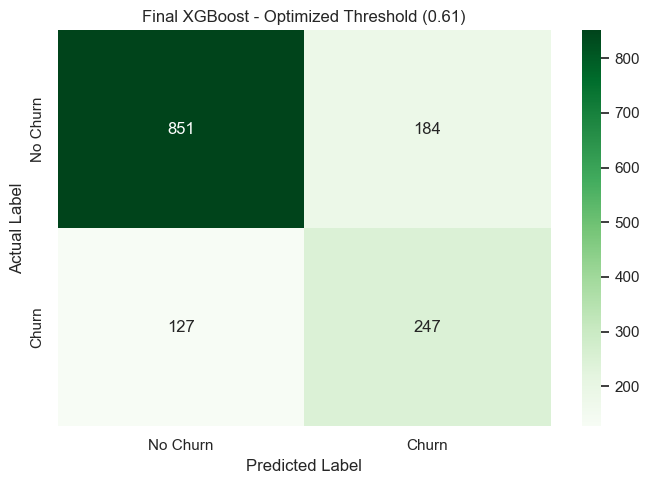

In [78]:
cm_final = confusion_matrix(y_test, y_final_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(cm_final,annot=True,fmt="d",cmap="Greens",xticklabels=["No Churn", "Churn"],yticklabels=["No Churn", "Churn"])

plt.title("Final XGBoost - Optimized Threshold (0.61)")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

 ## FINAL CLASSIFICATION REPORT

In [79]:
print("FINAL XGBOOST CLASSIFICATION REPORT")
print("=" * 50)

print(
    classification_report(
        y_test,
        y_final_pred,
        target_names=["No Churn", "Churn"],
        digits=4
    )
)

FINAL XGBOOST CLASSIFICATION REPORT
              precision    recall  f1-score   support

    No Churn     0.8701    0.8222    0.8455      1035
       Churn     0.5731    0.6604    0.6137       374

    accuracy                         0.7793      1409
   macro avg     0.7216    0.7413    0.7296      1409
weighted avg     0.7913    0.7793    0.7840      1409



## Save Final XGBoost Model

In [84]:
from pathlib import Path

PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name.lower() == "jupyter notebook"
    else Path.cwd()
)

print("Project Root:", PROJECT_ROOT)
print("Folder exists:", PROJECT_ROOT.exists())

Project Root: C:\Users\ABHINDEV S\OneDrive\Desktop\ChurnShield AI\ChurnShield-AI\note book
Folder exists: True


In [85]:
import joblib

In [86]:
# Save trained XGBoost model
joblib.dump(final_model,PROJECT_ROOT / "final_model.joblib")

# Save optimized threshold
joblib.dump(best_threshold,PROJECT_ROOT / "best_threshold.joblib")

# Save final model information
final_model_info = {
    "model_name": "XGBoost",
    "threshold": float(best_threshold),
    "accuracy": float(accuracy_score(y_test, y_final_pred)),
    "precision": float(precision_score(y_test, y_final_pred)),
    "recall": float(recall_score(y_test, y_final_pred)),
    "f1_score": float(f1_score(y_test, y_final_pred)),
    "roc_auc": float(roc_auc_score(y_test, y_final_prob))
}

joblib.dump(final_model_info,PROJECT_ROOT / "final_model_info.joblib")

print("Final model saved successfully!")

print("\nSaved files:")
print("1. final_model.joblib")
print("2. best_threshold.joblib")
print("3. final_model_info.joblib")

Final model saved successfully!

Saved files:
1. final_model.joblib
2. best_threshold.joblib
3. final_model_info.joblib
